# Amazon Fine Food Reviews: EDA and Sentiment Classification

**Goal:** explore patterns in Amazon Fine Food Reviews and train a baseline model to classify positive vs. negative review text. The dataset contains reviews, **not transaction or purchase records**.

**Source:** https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews

**Reproducibility:** Results are intentionally not pre-filled. Run all cells to obtain metrics on your local dataset.

## 1. Setup

Download the Kaggle dataset and put `database.sqlite` in the repository root (or set `AMAZON_REVIEWS_DB` to its path). Install packages from `requirements.txt` and launch Jupyter from the repository root.

In [4]:
from pathlib import Path
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

RANDOM_STATE = 42
MAX_ROWS = 100_000  # bounded sample for typical laptops; set to None for all rows
DB_PATH = Path.home() / "Downloads" / "Amazon-Fine-Food-Reviews-Analysis-main" / "database.sqlite"
if not DB_PATH.is_file():
    raise FileNotFoundError(f'Database not found: {DB_PATH.resolve()}. Download it from Kaggle and set AMAZON_REVIEWS_DB or put database.sqlite in the repository root.')

## 2. Load and validate reviews

A bounded random sample is used by default for manageable runtime. Because SQLite row sampling may be costly for large datasets, sampling is performed after selecting the required columns. `MAX_ROWS=None` uses the full dataset.

In [5]:
with sqlite3.connect(DB_PATH) as con:
    columns = pd.read_sql_query('PRAGMA table_info(Reviews)', con)['name'].tolist()
    required = {'ProductId', 'UserId', 'Score', 'Summary', 'Text'}
    if not required.issubset(columns):
        raise ValueError(f'Missing expected columns: {sorted(required - set(columns))}; found {columns}')
    reviews = pd.read_sql_query('SELECT ProductId, UserId, Score, Summary, Text FROM Reviews', con)
print(f'Loaded {len(reviews):,} reviews')
if MAX_ROWS is not None and len(reviews) > MAX_ROWS:
    reviews = reviews.sample(n=MAX_ROWS, random_state=RANDOM_STATE).copy()
print(f'Analyzing {len(reviews):,} reviews')
display(reviews.head())

Loaded 568,454 reviews
Analyzing 100,000 reviews


,ProductId,UserId,Score,Summary,Text
165256,B000EVG8J2,A1L01D2BD3RKVO,5,Crunchy & Good Gluten-Free Sandwich Cookies!,Having tried a couple of other brands of glute...
231465,B0000BXJIS,A3U62RE5XZDP0G,5,great kitty treats,My cat loves these treats. If ever I can't fin...
427827,B008FHUFAU,AOXC0JQQZGGB6,3,COFFEE TASTE,A little less than I expected. It tends to ha...
433954,B006BXV14E,A3PWPNZVMNX3PA,2,So the Mini-Wheats were too big?,"First there was Frosted Mini-Wheats, in origin..."
70260,B007I7Z3Z0,A1XNZ7PCE45KK7,5,Great Taste . . .,and I want to congratulate the graphic artist ...


## 3. Data quality and cleaning

Remove records with missing text or scores, standardize text, and drop exact duplicate review text to reduce train/test leakage. Duplicates can represent distinct reviews; this conservative choice is specifically for a text-classification baseline.

In [6]:
print('Missing values before cleaning:')
display(reviews.isna().sum().to_frame('missing'))
clean = reviews.dropna(subset=['Text', 'Score']).copy()
clean['Text'] = clean['Text'].astype(str).str.strip()
clean = clean.loc[clean['Text'].str.len().gt(0)].copy()
clean['Score'] = pd.to_numeric(clean['Score'], errors='coerce')
clean = clean.loc[clean['Score'].between(1, 5)].copy()
removed = clean.duplicated(subset=['Text']).sum()
clean = clean.drop_duplicates(subset=['Text']).copy()
clean['word_count'] = clean['Text'].str.split().str.len()
print(f'Rows after cleaning: {len(clean):,}; duplicate texts removed: {removed:,}')

Missing values before cleaning:


,missing
ProductId,0
UserId,0
Score,0
Summary,0
Text,0


Rows after cleaning: 87,592; duplicate texts removed: 12,408


## 4. Exploratory data analysis

These plots describe review scores and text, not verified purchases or sales.

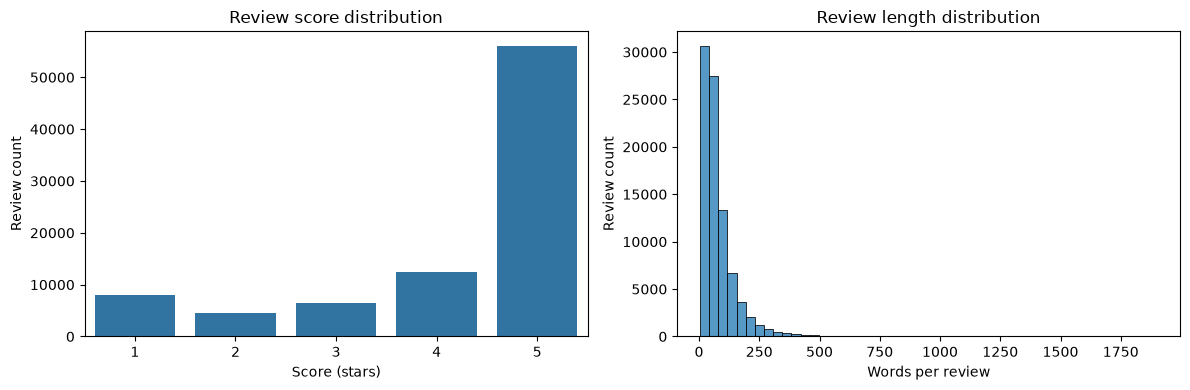

Score distribution (%):


Score
1     9.1
2     5.3
3     7.5
4    14.1
5    64.0
Name: percent, dtype: float64

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=clean, x='Score', order=[1,2,3,4,5], ax=axes[0])
axes[0].set(title='Review score distribution', xlabel='Score (stars)', ylabel='Review count')
sns.histplot(data=clean, x='word_count', bins=50, ax=axes[1])
axes[1].set(title='Review length distribution', xlabel='Words per review', ylabel='Review count')
plt.tight_layout()
plt.show()
print('Score distribution (%):')
display(clean['Score'].value_counts(normalize=True).sort_index().mul(100).round(1).rename('percent'))

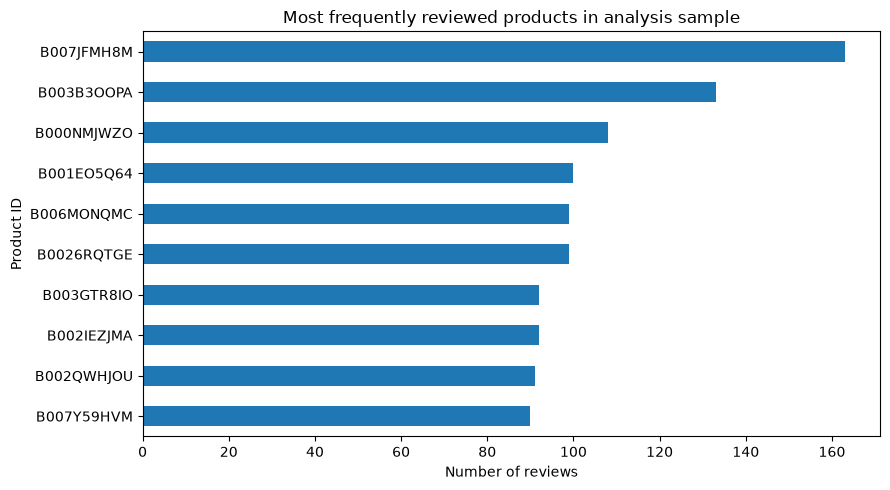

Median review length by score:


Score
1    62.0
2    66.0
3    70.0
4    65.0
5    52.0
Name: median_words, dtype: float64

In [8]:
top_products = clean['ProductId'].value_counts().head(10).sort_values()
ax = top_products.plot.barh(figsize=(9, 5), title='Most frequently reviewed products in analysis sample')
ax.set(xlabel='Number of reviews', ylabel='Product ID')
plt.tight_layout()
plt.show()
print('Median review length by score:')
display(clean.groupby('Score')['word_count'].median().rename('median_words'))

## 5. Define sentiment labels

Scores 1–2 are **negative**, scores 4–5 are **positive**. Exclude 3-star reviews because they are ambiguous. These are *rating-derived proxy labels*, not independently annotated sentiment. Do not use `Score` or `Summary` as model features.

In [9]:
model_df = clean.loc[clean['Score'].isin([1, 2, 4, 5]), ['Text', 'Score']].copy()
model_df['sentiment'] = (model_df['Score'] >= 4).astype(int)
print('Label counts (0=negative, 1=positive):')
print(model_df['sentiment'].value_counts().sort_index())
if model_df['sentiment'].nunique() < 2 or model_df['sentiment'].value_counts().min() < 2:
    raise ValueError('Not enough examples of both classes for a stratified split.')

Label counts (0=negative, 1=positive):
sentiment
0    12588
1    68453
Name: count, dtype: int64


## 6. Train/test split and baseline

TF-IDF is fitted **only on training data** via a pipeline. A stratified split preserves class proportions. The majority-class baseline helps contextualize model accuracy.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(model_df['Text'], model_df['sentiment'], test_size=0.20, random_state=RANDOM_STATE, stratify=model_df['sentiment'])
majority_baseline = y_test.value_counts(normalize=True).max()
model = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, stop_words='english', ngram_range=(1,2), min_df=2, max_features=50_000)),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f'Majority-class baseline accuracy: {majority_baseline:.3f}')
print(f'Model test accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(f'Model test macro F1: {f1_score(y_test, y_pred, average="macro"):.3f}')
print(classification_report(y_test, y_pred, target_names=['negative', 'positive'], digits=3))

Majority-class baseline accuracy: 0.845
Model test accuracy: 0.902
Model test macro F1: 0.835
              precision    recall  f1-score   support

    negative      0.640     0.849     0.730      2518
    positive      0.971     0.912     0.940     13691

    accuracy                          0.902     16209
   macro avg      0.805     0.881     0.835     16209
weighted avg      0.919     0.902     0.908     16209



## 7. Confusion matrix and interpretation

Review both classes' precision and recall. Because positive reviews often dominate, accuracy alone can be misleading.

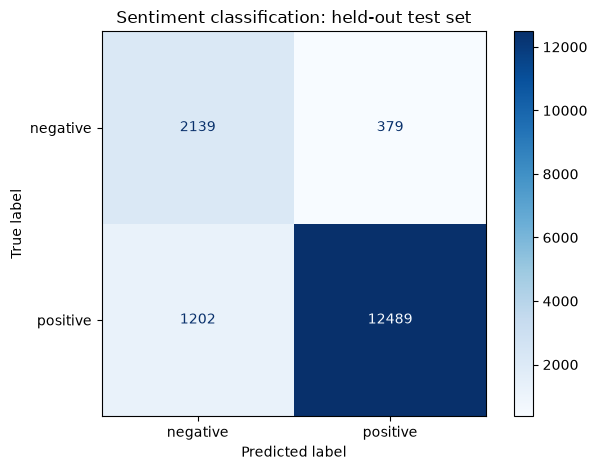

Features associated with negative ratings: disappointed, worst, disappointing, terrible, awful, unfortunately, horrible, thought, weak, return, stale, bad, disappointment, nasty, maybe
Features associated with positive ratings: great, delicious, best, perfect, love, loves, excellent, good, wonderful, nice, favorite, amazing, awesome, highly, yummy


In [11]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['negative', 'positive'], cmap='Blues', values_format='d')
plt.title('Sentiment classification: held-out test set')
plt.tight_layout()
plt.show()
features = np.array(model.named_steps['tfidf'].get_feature_names_out())
weights = model.named_steps['classifier'].coef_[0]
print('Features associated with negative ratings:', ', '.join(features[np.argsort(weights)[:15]]))
print('Features associated with positive ratings:', ', '.join(features[np.argsort(weights)[-15:][::-1]]))

## 8. Limitations and next steps

- The labels are inferred from star ratings; sarcasm, mixed reviews, and neutral 3-star reviews are not modeled.
- Sampling changes the analyzed population; results can differ when `MAX_ROWS` changes.
- Duplicate text is removed, but near-duplicates and product/user correlations may still inflate generalization estimates.
- A random review-level split measures performance on held-out reviews, **not** unseen products or users. A grouped split would provide a tougher test.
- Compare with a majority-class baseline and report per-class metrics, not accuracy alone.
- Future work: grouped evaluation by `ProductId`, hyperparameter tuning on a validation set, and error analysis.

**Portfolio summary:** This notebook demonstrates data validation, reproducible EDA, feature engineering, leakage-aware modeling, and honest evaluation.